El uso de Seaborn para visualización es muy poderoso, pero requiere aplicar criterios claros para que los gráficos realmente comuniquen lo que queremos. En esta sección repasamos buenas prácticas, errores comunes y cómo combinar Seaborn con Matplotlib para lograr resultados profesionales.

10.1 Elegir el gráfico adecuado para cada tipo de variable
Un paso clave en cualquier análisis es seleccionar el gráfico que mejor represente la relación que queremos mostrar:

Una sola variable (univariado):
Numérica → histplot, kdeplot, boxplot, violinplot.
Categórica → countplot (o barplot con conteo).
Dos variables (bivariado):
Numéricas → scatterplot, lineplot, jointplot (si queremos añadir distribuciones marginales).
Categórica + numérica → barplot, boxplot, violinplot, swarmplot.
Más de dos variables (multivariado):
hue, style, size para codificar variables adicionales en un solo gráfico.
pairplot para ver todas las relaciones numéricas.
FacetGrid/relplot/catplot para separar por categorías (columnas y filas).
Regla práctica: pensá primero qué pregunta querés responder con el gráfico. El tipo de variable (numérica/categórica) te guiará hacia la visualización adecuada.

10.2 Evitar errores comunes en visualización
❌ Errores frecuentes
Usar colores secuenciales para categorías (ej. países, sexos): puede confundir al lector.
Mostrar datos sin escalas consistentes (ej. heatmaps sin fijar vmin/vmax).
Sobrecargar un gráfico con demasiadas categorías o colores → mejor usar facetas.
Usar gráficos llamativos pero poco informativos (ej. pastel/3D).
No rotar etiquetas o no ajustar tamaños, generando gráficos ilegibles.
Interpretar la línea de regresión como causalidad directa (recordá: correlación ≠ causalidad).
✅ Buenas prácticas
Elegí paletas cualitativas para categorías y secuenciales/divergentes para valores numéricos.
Usá alpha (transparencia) en scatterplot cuando haya muchos puntos.
Ordená categorías en ejes (order=... en barplot, boxplot) para dar más claridad.
Mantené etiquetas, títulos y leyendas claras y concisas.
Sumá anotaciones cuando quieras remarcar un valor clave.
10.3 Cómo combinar Seaborn con Matplotlib
Seaborn simplifica los gráficos, pero Matplotlib ofrece control fino sobre:

Títulos y subtítulos con distintos tamaños.
Límites y ticks en los ejes.
Anotaciones, flechas y textos dentro del gráfico.
Guardado en alta resolución y diferentes formatos.
Ejemplo A) Personalizar título y ejes

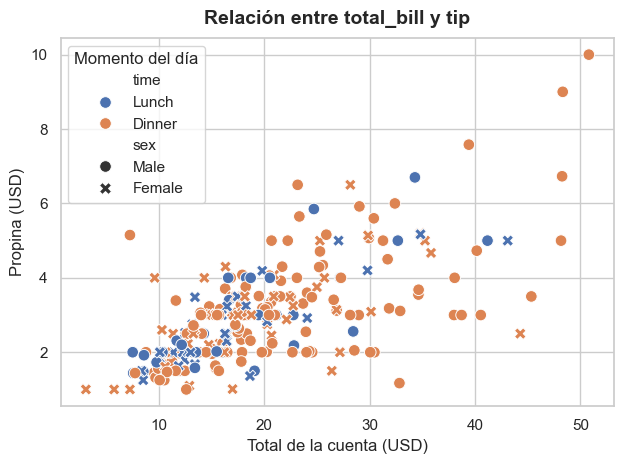

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
tips = sns.load_dataset("tips")

ax = sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", style="sex", s=70)

# Ajustes con Matplotlib
ax.set_title("Relación entre total_bill y tip", fontsize=14, weight="bold", pad=10)
ax.set_xlabel("Total de la cuenta (USD)", fontsize=12)
ax.set_ylabel("Propina (USD)", fontsize=12)
ax.legend(title="Momento del día", loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

Ejemplo B) Añadir anotaciones a un gráfico

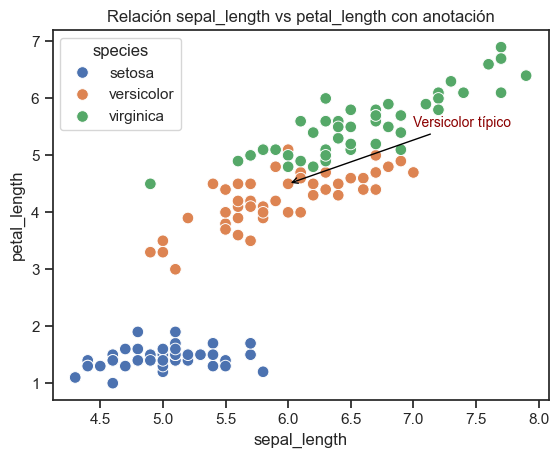

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="ticks")
iris = sns.load_dataset("iris")

ax = sns.scatterplot(data=iris, x="sepal_length", y="petal_length", hue="species", s=70)

# Agregar anotación Matplotlib
ax.annotate("Versicolor típico", xy=(6, 4.5), xytext=(7, 5.5),
            arrowprops=dict(arrowstyle="->", color="black"),
            fontsize=10, color="darkred")
plt.title("Relación sepal_length vs petal_length con anotación")
plt.show()

Ejemplo C) Ajustar layout y guardar imagen

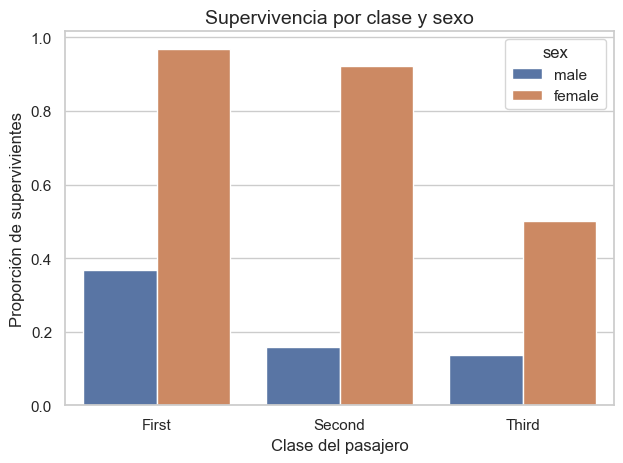

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
titanic = sns.load_dataset("titanic")

ax = sns.barplot(data=titanic, x="class", y="survived", hue="sex", errorbar=None)

plt.title("Supervivencia por clase y sexo", fontsize=14)
plt.xlabel("Clase del pasajero")
plt.ylabel("Proporción de supervivientes")
plt.tight_layout()

# Guardar en alta resolución
plt.savefig("titanic_supervivencia.png", dpi=300)
plt.show()

10.4 Conclusiones
Seaborn permite crear gráficos elegantes y estadísticamente útiles con muy poco código, trabajando directamente con DataFrames de Pandas.
La clave está en elegir la visualización adecuada según el tipo de variable y la pregunta de análisis.
Evitar malas prácticas de color, escala y saturación de información asegura que tus gráficos comuniquen claramente.
La combinación con Matplotlib te da control total: desde anotaciones y ajustes finos hasta exportación de imágenes profesionales.
Usar datasets clásicos (Tips, Iris, Titanic) es un excelente entrenamiento, pero la verdadera utilidad aparece cuando aplicás estas técnicas a tus propios datos reales.